# 01 — Indic Prompt Compressor: first experiment on DeepSeek V4.1 Flash

**Target model:** `deepseekv4.1-flash-1017` via the Sarvam API, **thinking OFF** · **Judge:** `sarvam-105b` · **Languages:** hi, kn, ta · **Tasks:** QA, summarisation

What this notebook does, top to bottom:

| Part | What | Needs |
|---|---|---|
| A | **Measure the gap**: parity ratio per tokenizer on FLORES+ (DeepSeek, GLM-5.3, Gemma 4, Sarvam, GPT-4o) | tokenizers only |
| B | Build frozen eval samples (IndicQA → QA + summarisation) | data |
| C | **Apply compression methods** M1–M6 locally (GPU stages run one at a time) | local models |
| D | Offline **upper bound** of token savings (no API) | tokenizers |
| E | Send every variant to DeepSeek (thinking off), back-translate English answers locally | Sarvam API |
| F | **Judge** with `sarvam-105b` + token-F1 + LaBSE fidelity | Sarvam API |
| G | **Results**: savings vs quality retained, τ = 95%, bootstrap CIs, Pareto plots, projected GLM-5.3 savings | — |
| H | Judge validation: gold anchoring + **Hindi spot-check sheet** for you | — |

**Before running:** `uv sync` → fill `.env` (`SARVAM_API_KEY`, `HF_TOKEN`) → `uv run python scripts/download_assets.py`.
Start with `SMOKE = True` (5 items per cell, ~5 min); switch to `False` for the real run (50 per cell).
All API responses are cached in `cache/`, so re-running costs nothing.

| Method | Description |
|---|---|
| M0 | raw prompt (baseline); **M0_rep** = same prompt sent again, to measure the noise floor |
| M1 | Unicode NFC, strip zero-width chars / citation marks / whitespace, drop duplicate sentences |
| M2 | M1 + LLMLingua-2 token pruning on the native-script context |
| M3 | M1 + IndicTrans2 → English prompt, English answer, IndicTrans2 back to the source language |
| M3b | (optional) same as M3, but local sarvam-translate GGUF via Ollama for the forward translation |
| M4 | M1 + rule-based romanisation (ITRANS), answer in native script |
| M4b | (optional) natural romanisation via Sarvam `/transliterate` (paid ₹2/1k chars, counted as overhead) |
| M5 | M3 + LLMLingua-2 on the English context, keep 60% |
| **M5_80** | M3 + LLMLingua-2 on the English context, keep 80% (gentler M5) |
| **M3_b5** | M3 with IndicTrans2 beam search 5 (instead of 2) in both directions: better translation (Tamil fix a) |
| **M3h** | (QA only) hybrid: beam-5 English context + the 2 original-script sentences most similar to the question; answer directly in the source language, no back-translation (Tamil fix c) |
| M6 | M1 native prompt, but the **answer** is in English → translated back (output-side saving) |

## 0. Config

In [1]:
# ======================= CONFIG =======================
SMOKE = False                      # True: 5 items per (lang, task). False: real run (N_FULL items)
N_FULL = 50
SEED = 42
LANGS = ["hi", "kn", "ta"]
TASKS = ["qa", "summ"]

TARGET_MODEL = "deepseekv4.1-flash-1017"
TARGET_EXTRA = {"temperature": 0, "reasoning_effort": "none"}     # thinking OFF
JUDGE_MODEL = "sarvam-105b"
JUDGE_EXTRA = {"temperature": 0, "reasoning_effort": "none"}   # thinking OFF: "low" still thought >4000 tokens -> empty verdicts
MAX_TOKENS = {"qa": 256, "summ": 700}
JUDGE_MAX_TOKENS = 800

SARVAM_BASE = "https://api.sarvam.ai"
RPM = {TARGET_MODEL: 45, JUDGE_MODEL: 55, "text-api": 55}   # stay under the pay-as-you-go limits (50 / 60 / 60)
MAX_CONCURRENCY = 8

# ₹ per 1M tokens (input, output). Sarvam pricing page, read 2026-11-07
PRICES = {"deepseekv4.1-flash-1017": (25, 105), "glm5.3": (126, 390), "glm5.3-flash": (13.5, 45),
          "sarvam-105b": (15, 60), "gemma4": (35, 90)}
SARVAM_TEXT_API_RS_PER_1K_CHARS = 2.0

LLMLINGUA_RATES = [0.4, 0.6, 0.8]  # M2 sweep: fraction of tokens LLMLingua-2 keeps -> methods M2_40 / M2_60 / M2_80
M5_VARIANTS = {"M5": 0.6, "M5_80": 0.8}   # LLMLingua-2 keep-rate on the English context (M5 keeps its old name)
IT2_BEAMS_HQ = 5                   # M3_b5 / M3h: beam size for the "high-quality" IndicTrans2 pass
IT2_BATCH_HQ = 4                   # smaller batch for beam 5 on the 4 GB GPU
HYBRID_TOP_K = 2                   # M3h: original-script sentences kept next to the English context
M3H_TASKS = ["qa"]                 # M3h only makes sense with a question
M6_TASKS = ["summ"]                # M6 (answer in English) only where output is long; it broke short QA answers
TAU = 0.95                        # quality threshold (quality retained vs M0)
BOOTSTRAP = 2000

USE_OLLAMA_SARVAM_TRANSLATE = False   # adds M3b (needs `ollama serve` + `download_assets.py --ollama`)
USE_SARVAM_TRANSLITERATE_API = False  # adds M4b (paid API; counted as overhead)
OLLAMA_URL = "http://localhost:11434"
OLLAMA_MODEL = "hf.co/fischerman/sarvam-translate-gguf:Q4_K_S"

N_PER_CELL = 5 if SMOKE else N_FULL
METHODS = ["M0", "M0_rep", "M1"] + [f"M2_{int(r * 100)}" for r in LLMLINGUA_RATES] + ["M3", "M4", "M5", "M6", "M3_b5", "M5_80", "M3h"]
if USE_OLLAMA_SARVAM_TRANSLATE: METHODS.append("M3b")
if USE_SARVAM_TRANSLITERATE_API: METHODS.append("M4b")
print("items per (lang, task):", N_PER_CELL, "| methods:", METHODS)

items per (lang, task): 50 | methods: ['M0', 'M0_rep', 'M1', 'M2_40', 'M2_60', 'M2_80', 'M3', 'M4', 'M5', 'M6', 'M3_b5', 'M5_80', 'M3h']


In [2]:
import os, re, gc, json, time, math, random, hashlib, asyncio, unicodedata
from pathlib import Path
from collections import defaultdict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less fragmentation on 4 GB
os.environ.setdefault("TIKTOKEN_CACHE_DIR", str(ROOT / "models" / "tiktoken"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import httpx
from dotenv import load_dotenv
from tqdm.auto import tqdm
from tqdm.asyncio import tqdm_asyncio
from tokenizers import Tokenizer
import tiktoken
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate

load_dotenv(ROOT / ".env")
SARVAM_API_KEY = os.environ.get("SARVAM_API_KEY", "")
assert SARVAM_API_KEY, "Set SARVAM_API_KEY in .env"

RAW, SAMPLES = ROOT / "data" / "raw", ROOT / "data" / "samples"
CACHE = ROOT / "cache" / "api"
OUT = ROOT / "results" / ("01_deepseek_smoke" if SMOKE else "01_deepseek")
FIG = OUT / "figures"
for p in (SAMPLES, CACHE, FIG): p.mkdir(parents=True, exist_ok=True)

LANG = {
    "hi": dict(name="Hindi",   script="Devanagari", it2="hin_Deva", flores="hin_Deva", sarvam="hi-IN", scheme=sanscript.DEVANAGARI),
    "kn": dict(name="Kannada", script="Kannada",    it2="kan_Knda", flores="kan_Knda", sarvam="kn-IN", scheme=sanscript.KANNADA),
    "ta": dict(name="Tamil",   script="Tamil",      it2="tam_Taml", flores="tam_Taml", sarvam="ta-IN", scheme=sanscript.TAMIL),
}
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
print("ROOT:", ROOT, "| results ->", OUT)

ROOT: /home/sg/REPOs/projects/onspot-hackathon | results -> /home/sg/REPOs/projects/onspot-hackathon/results/01_deepseek


## 1. Tokenizers
Offline token counters for each model. The Sarvam ids are matched to Hugging Face tokenizers **by name**. Section E checks the DeepSeek count against the API's `usage.prompt_tokens`.

In [3]:
TOK_DIR = ROOT / "models" / "tokenizers"
TOKENIZERS = {}
for mid in ["deepseekv4.1-flash-1017", "glm5.3", "gemma4", "sarvam-105b"]:
    f = TOK_DIR / mid / "tokenizer.json"
    if f.exists():
        TOKENIZERS[mid] = Tokenizer.from_file(str(f))
    else:
        print("missing tokenizer:", f)
_o200k = tiktoken.get_encoding("o200k_base")

def ntok(model, text):
    if not text: return 0
    if model == "gpt-4o (o200k)": return len(_o200k.encode(text))
    return len(TOKENIZERS[model].encode(text, add_special_tokens=False).ids)

TOK_MODELS = list(TOKENIZERS) + ["gpt-4o (o200k)"]
print("tokenizers:", TOK_MODELS)

tokenizers: ['deepseekv4.1-flash-1017', 'glm5.3', 'gemma4', 'sarvam-105b', 'gpt-4o (o200k)']


## 2. Text utilities (M1 normalisation, sentence split, M4 romanisation)

In [4]:
_ZW = dict.fromkeys(map(ord, "​‌‍⁠﻿­"), None)
_SENT = re.compile(r"(?<=[.!?।॥])\s+")      # . ! ? । ॥

def split_sents(text):
    return [s.strip() for s in _SENT.split(text) if s.strip()]

def m1_normalize(text):
    """Lossless-ish cleanup: NFC, zero-width chars, wiki citation marks, whitespace, duplicate sentences."""
    t = unicodedata.normalize("NFC", text).translate(_ZW)
    t = re.sub(r"\[\s*\d+\s*\]", "", t)
    t = re.sub(r"[ \t ]+", " ", t)
    t = re.sub(r"\s*\n\s*", "\n", t).strip()
    seen, out = set(), []
    for s in split_sents(t):
        key = re.sub(r"\W+", "", s)
        if key and key in seen: continue
        seen.add(key); out.append(s)
    return " ".join(out)

def m4_romanize(text, lang):
    return transliterate(text, LANG[lang]["scheme"], sanscript.ITRANS)

def chunk_text(text, max_chars):
    """Greedy sentence packing into chunks <= max_chars (for char-limited APIs)."""
    chunks, cur = [], ""
    for s in split_sents(text) or [text]:
        while len(s) > max_chars:
            chunks.append(s[:max_chars]); s = s[max_chars:]
        if len(cur) + len(s) + 1 > max_chars and cur:
            chunks.append(cur); cur = s
        else:
            cur = (cur + " " + s).strip()
    if cur: chunks.append(cur)
    return chunks

def free_gpu():
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    except ImportError:
        pass

print(m1_normalize("यह   एक वाक्य है।[1]  यह   एक वाक्य है। दूसरा‌ वाक्य।"))
print(m4_romanize("सरकार ने नई योजना की घोषणा की।", "hi"))

यह एक वाक्य है। दूसरा वाक्य।
sarakAra ne naI yojanA kI ghoShaNA kI|


## A. Measure the gap (FLORES+ devtest, ~1000 parallel sentences)
**Parity** = tokens(language) / tokens(English) for the same content. **Fertility** = tokens per whitespace word.
The `M1` and `M4 (ITRANS)` columns are the offline upper bound for those methods. M3 (via English) would reach parity 1.0 if the translation were perfect.

In [5]:
def read_jsonl(p):
    with open(p, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

flores = {}
for code in ["eng_Latn", "hin_Deva", "kan_Knda", "tam_Taml"]:
    rows = read_jsonl(RAW / "flores" / f"{code}.jsonl")
    flores[code] = {r.get("id", i): (r.get("text") or r.get("sentence")) for i, r in enumerate(rows)}
ids = sorted(set.intersection(*[set(v) for v in flores.values()]), key=str)
print("aligned FLORES sentences:", len(ids))

gap_rows = []
for model in TOK_MODELS:
    en_tok = sum(ntok(model, flores["eng_Latn"][i]) for i in ids)
    en_words = sum(len(flores["eng_Latn"][i].split()) for i in ids)
    gap_rows.append(dict(tokenizer=model, lang="en", variant="native", tokens=en_tok, parity=1.0, fertility=en_tok / en_words))
    for lang in LANGS:
        code = LANG[lang]["flores"]
        texts = [flores[code][i] for i in ids]
        words = sum(len(t.split()) for t in texts)
        for variant, fn in [("native", lambda t: t), ("M1", m1_normalize), ("M4 ITRANS", lambda t, l=lang: m4_romanize(t, l))]:
            tok = sum(ntok(model, fn(t)) for t in texts)
            gap_rows.append(dict(tokenizer=model, lang=lang, variant=variant, tokens=tok, parity=tok / en_tok, fertility=tok / words))
gap = pd.DataFrame(gap_rows)
gap.to_csv(OUT / "gap_flores.csv", index=False)

parity = gap[gap.variant == "native"].pivot(index="tokenizer", columns="lang", values="parity")[["en"] + LANGS]
print("Parity ratio vs English (native script):"); display(parity.round(2))
print("Effect of M1 / ITRANS romanisation on parity:")
display(gap[gap.lang != "en"].pivot_table(index=["tokenizer", "lang"], columns="variant", values="parity").round(2))

aligned FLORES sentences: 1012
Parity ratio vs English (native script):


lang,en,hi,kn,ta
tokenizer,,,,
deepseekv4.1-flash-1017,1.0,2.79,3.69,3.07
gemma4,1.0,1.31,1.92,1.47
glm5.3,1.0,4.31,8.85,7.64
gpt-4o (o200k),1.0,1.57,1.97,1.98
sarvam-105b,1.0,1.31,1.51,1.47


Effect of M1 / ITRANS romanisation on parity:


variant                         M1  M4 ITRANS  native
tokenizer               lang                         
deepseekv4.1-flash-1017 hi    2.79       2.53    2.79
                        kn    3.63       2.70    3.69
                        ta    3.07       3.64    3.07
gemma4                  hi    1.31       2.38    1.31
                        kn    1.90       2.53    1.92
                        ta    1.46       3.38    1.47
glm5.3                  hi    4.32       2.52    4.31
                        kn    8.82       2.69    8.85
                        ta    7.64       3.89    7.64
gpt-4o (o200k)          hi    1.57       2.39    1.57
                        kn    1.95       2.50    1.97
                        ta    1.98       3.42    1.98
sarvam-105b             hi    1.31       2.38    1.31
                        kn    1.47       2.53    1.51
                        ta    1.46       3.38    1.47

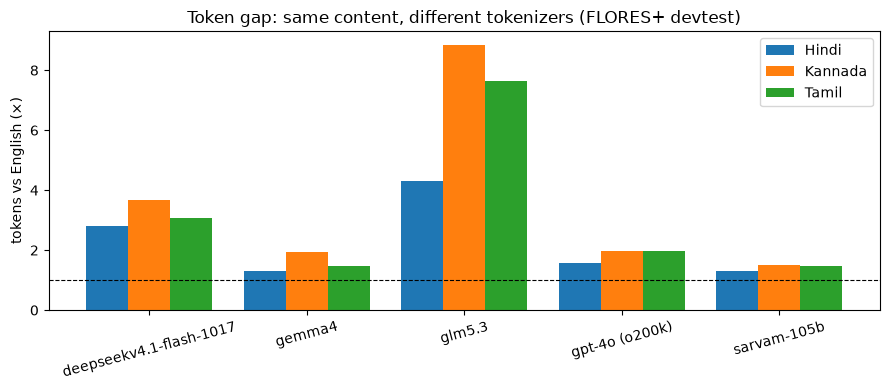

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
p = parity[LANGS]
x = np.arange(len(p.index)); w = 0.8 / len(LANGS)
for k, lang in enumerate(LANGS):
    ax.bar(x + k * w, p[lang], w, label=LANG[lang]["name"])
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(x + w * (len(LANGS) - 1) / 2, p.index, rotation=15)
ax.set_ylabel("tokens vs English (×)"); ax.set_title("Token gap: same content, different tokenizers (FLORES+ devtest)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "gap_parity.png", dpi=150); plt.show()

## B. Frozen evaluation samples (IndicQA)
- **QA:** answerable questions, one per context paragraph, context 300–2500 chars.
- **Summarisation:** a different set of IndicQA paragraphs (≥ 600 chars). It is **reference-free**: quality = judge score + fidelity to the M0 summary.

Samples are frozen to `data/samples/` (100 per cell). Smoke and full runs both take the first N, so smoke results stay a subset of the full run.

In [7]:
def load_indicqa(lang):
    d = json.load(open(RAW / "indicqa" / f"indicqa.{lang}.json", encoding="utf-8"))
    rows = []
    for art in d["data"]:
        for para in art["paragraphs"]:
            ctx = para["context"].strip()
            for qa in para["qas"]:
                ans = [a["text"].strip() for a in qa.get("answers", []) if a.get("text", "").strip()]
                rows.append(dict(qid=str(qa["id"]), context=ctx, question=qa["question"].strip(), answers=ans))
    return rows

def freeze_samples(lang, n_freeze=100):
    f_qa, f_su = SAMPLES / f"qa_{lang}.jsonl", SAMPLES / f"summ_{lang}.jsonl"
    if f_qa.exists() and f_su.exists():
        return read_jsonl(f_qa), read_jsonl(f_su)
    rows = load_indicqa(lang)
    by_ctx = defaultdict(list)
    for r in rows: by_ctx[r["context"]].append(r)
    ctxs = sorted(by_ctx)
    rng = random.Random(SEED); rng.shuffle(ctxs)
    qa, su = [], []
    for c in ctxs:
        if len(qa) < n_freeze and 300 <= len(c) <= 2500:
            answerable = [r for r in by_ctx[c] if r["answers"]]
            if answerable:
                r = answerable[0]
                qa.append(dict(item_id=f"qa-{lang}-{r['qid']}", lang=lang, task="qa", context=c, question=r["question"], answers=r["answers"]))
                continue
        if len(su) < n_freeze and 600 <= len(c) <= 3000:
            su.append(dict(item_id=f"summ-{lang}-{hashlib.md5(c.encode()).hexdigest()[:10]}", lang=lang, task="summ", context=c, question=None, answers=None))
        if len(qa) >= n_freeze and len(su) >= n_freeze: break
    for f, data in ((f_qa, qa), (f_su, su)):
        with open(f, "w", encoding="utf-8") as fh:
            for r in data: fh.write(json.dumps(r, ensure_ascii=False) + "\n")
    return qa, su

ITEMS = []
for lang in LANGS:
    qa, su = freeze_samples(lang)
    if "qa" in TASKS: ITEMS += qa[:N_PER_CELL]
    if "summ" in TASKS: ITEMS += su[:N_PER_CELL]
items_df = pd.DataFrame(ITEMS)
print(items_df.groupby(["lang", "task"]).size().rename("n").to_frame().T)
items_df.head(3)

lang  hi       kn       ta     
task  qa summ  qa summ  qa summ
n     50   50  50   50  50   50


,item_id,lang,task,context,question,answers
0,qa-hi-52,hi,qa,"1960 और 1970 के दशक के दौरान, भारत ने अपने राजनीतिक और आर्थिक आधार के कारण स...",एसएलवी -3 की पहली प्रायोगिक उड़ान कब हुई थी?,[अगस्त 1979]
1,qa-hi-950,hi,qa,बंगाल की खाड़ी एक क्षारीय जल का सागर है। यह हिन्द महासागर का भाग है। पृथ्वी ...,बंगाल की खाड़ी के नीचे की प्लेट को क्या कहा जाता है?,[विवर्तनिक प्लेट्स]
2,qa-hi-30,hi,qa,10-12 साल हिन्दू धर्म के अन्तर्गत रहते हुए बाबासाहब आम्बेडकर ने हिन्दू धर्म ...,मनष्य धर्म के लिए नहीं बल्कि धर्म मनुष्य के लिए है यह किसका मानना था ?,[आम्बेडकर]


## C. Compression methods (local)
GPU stages run **one model at a time** (4 GB VRAM): IndicTrans2 indic→en → LLMLingua-2 → (optional) Ollama sarvam-translate.
For every item we store text variants `V[item_id][variant]` and the local processing time (overhead).

In [8]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

V = {it["item_id"]: {} for it in ITEMS}          # text variants per item
OVERHEAD_S = defaultdict(lambda: defaultdict(float))   # item_id -> method -> local seconds
OVERHEAD_RS = defaultdict(lambda: defaultdict(float))  # item_id -> method -> paid-API rupees

for it in ITEMS:
    v = V[it["item_id"]]
    v["ctx_raw"], v["q_raw"] = it["context"], it["question"] or ""
    t0 = time.perf_counter()
    v["ctx_m1"], v["q_m1"] = m1_normalize(it["context"]), m1_normalize(it["question"] or "")
    OVERHEAD_S[it["item_id"]]["M1"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    v["ctx_rom"], v["q_rom"] = m4_romanize(v["ctx_m1"], it["lang"]), m4_romanize(v["q_m1"], it["lang"])
    OVERHEAD_S[it["item_id"]]["M4"] = OVERHEAD_S[it["item_id"]]["M1"] + time.perf_counter() - t0
    for m in ("M3", "M5", "M6", "M3_b5", "M5_80", "M3h"):          # these build on M1 output
        OVERHEAD_S[it["item_id"]][m] += OVERHEAD_S[it["item_id"]]["M1"]
print("M1/M4 done for", len(ITEMS), "items")

device: cuda NVIDIA GeForce RTX 3050 Ti Laptop GPU
M1/M4 done for 300 items


### C1. IndicTrans2 (distilled 200M), sentence-level translation

In [9]:
IT2_BATCH, IT2_BEAMS = 8, 2      # beams 5 -> 2: ~2x faster translation      # lower IT2_BATCH (e.g. 4) if you still hit CUDA OOM on the 4 GB GPU

class IndicTrans2:
    def __init__(self, direction):   # "indic-en" or "en-indic"
        try:
            from IndicTransToolkit import IndicProcessor
        except ImportError:
            from IndicTransToolkit.processor import IndicProcessor
        name = f"ai4bharat/indictrans2-{direction}-dist-200M"
        self.tok = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            name, trust_remote_code=True, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32
        ).to(DEVICE).eval()
        # IndicTrans2's remote code only understands legacy tuple KV caches. transformers >= 4.5x passes a Cache object
        # (-> "'NoneType' object has no attribute 'shape'"). Declaring no default-cache support makes generate() keep
        # tuples, and the model's own _reorder_cache handles beam search.
        type(self.model)._supports_default_dynamic_cache = classmethod(lambda cls: False)
        self.ip = IndicProcessor(inference=True)

    @torch.inference_mode()
    def _generate(self, enc, beams):
        return self.model.generate(**enc, use_cache=True, min_length=0, max_length=256,
                                   num_beams=beams, num_return_sequences=1)

    def translate_sents(self, sents, src, tgt, bs=IT2_BATCH, beams=IT2_BEAMS):
        uniq = sorted(set(sents), key=len)
        out = {}
        for i in tqdm(range(0, len(uniq), bs), desc=f"IT2 {src}->{tgt}", leave=False):
            batch = uniq[i:i + bs]
            pre = self.ip.preprocess_batch(batch, src_lang=src, tgt_lang=tgt)
            enc = self.tok(pre, truncation=True, padding="longest", return_tensors="pt", return_attention_mask=True).to(DEVICE)
            dec = self.tok.batch_decode(self._generate(enc, beams), skip_special_tokens=True, clean_up_tokenization_spaces=True)
            for s, t in zip(batch, self.ip.postprocess_batch(dec, lang=tgt)):
                out[s] = t
        return [out[s] for s in sents]

    def translate_texts(self, texts, src, tgt, bs=IT2_BATCH, beams=IT2_BEAMS):
        """Translate paragraphs: split into sentences, translate, re-join. Returns (translations, seconds)."""
        t0 = time.perf_counter()
        parts = [split_sents(t) or ([t] if t else []) for t in texts]
        flat = [s for p in parts for s in p]
        tr = iter(self.translate_sents(flat, src, tgt, bs=bs, beams=beams)) if flat else iter([])
        res = [" ".join(next(tr) for _ in p) for p in parts]
        return res, time.perf_counter() - t0

    def close(self):
        del self.model, self.tok; free_gpu()

def charge_time(item_ids, texts, seconds, method_keys):
    """Split batch time across items in proportion to their characters."""
    total = sum(len(t) for t in texts) or 1
    for iid, t in zip(item_ids, texts):
        for m in method_keys:
            OVERHEAD_S[iid][m] += seconds * len(t) / total

it2 = IndicTrans2("indic-en")
for lang in LANGS:
    its = [it for it in ITEMS if it["lang"] == lang]
    if not its: continue
    src = LANG[lang]["it2"]
    ctx_en, s1 = it2.translate_texts([V[it["item_id"]]["ctx_m1"] for it in its], src, "eng_Latn")
    q_en, s2 = it2.translate_texts([V[it["item_id"]]["q_m1"] for it in its], src, "eng_Latn")
    for it, c, q in zip(its, ctx_en, q_en):
        V[it["item_id"]]["ctx_en"], V[it["item_id"]]["q_en"] = c, q
    ids_ = [it["item_id"] for it in its]
    charge_time(ids_, [V[i]["ctx_m1"] + V[i]["q_m1"] for i in ids_], s1 + s2, ["M3", "M5", "M5_80"])
    if {"M3_b5", "M3h"} & set(METHODS):   # high-quality pass (beam 5) for M3_b5 and M3h
        ctx_hq, s3 = it2.translate_texts([V[i]["ctx_m1"] for i in ids_], src, "eng_Latn", bs=IT2_BATCH_HQ, beams=IT2_BEAMS_HQ)
        q_hq, s4 = it2.translate_texts([V[i]["q_m1"] for i in ids_], src, "eng_Latn", bs=IT2_BATCH_HQ, beams=IT2_BEAMS_HQ)
        for i, c, q in zip(ids_, ctx_hq, q_hq):
            V[i]["ctx_en_b5"], V[i]["q_en_b5"] = c, q
        charge_time(ids_, [V[i]["ctx_m1"] + V[i]["q_m1"] for i in ids_], s3 + s4, ["M3_b5", "M3h"])
it2.close()
ex = ITEMS[0]["item_id"]; print(V[ex]["ctx_m1"][:200], "\n->", V[ex]["ctx_en"][:200])
if "ctx_en_b5" in V[ex]: print("beam 5 ->", V[ex]["ctx_en_b5"][:200])

`torch_dtype` is deprecated! Use `dtype` instead!


IT2 hin_Deva->eng_Latn:   0%|          | 0/234 [00:00<?, ?it/s]

/home/sg/REPOs/projects/onspot-hackathon/.venv/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


IT2 hin_Deva->eng_Latn:   0%|          | 0/7 [00:00<?, ?it/s]

IT2 hin_Deva->eng_Latn:   0%|          | 0/467 [00:00<?, ?it/s]

IT2 hin_Deva->eng_Latn:   0%|          | 0/13 [00:00<?, ?it/s]

... (5 outputs left out)

IT2 tam_Taml->eng_Latn:   0%|          | 0/7 [00:00<?, ?it/s]

IT2 tam_Taml->eng_Latn:   0%|          | 0/412 [00:00<?, ?it/s]

IT2 tam_Taml->eng_Latn:   0%|          | 0/13 [00:00<?, ?it/s]

1960 और 1970 के दशक के दौरान, भारत ने अपने राजनीतिक और आर्थिक आधार के कारण से स्वयं के प्रक्षेपण यान कार्यक्रम की शुरूआत की। 1960-1970 के दशक में, देश में सफलतापूर्वक साउंडिंग रॉकेट कार्यक्रम विकसित क 
-> During the 1960s and 1970s, India embarked on its own launch vehicle programme due to its political and economic base. In the decade of 1960-1970, the country successfully developed the sounding rocke
beam 5 -> During the 1960s and 1970s, India introduced its own launch vehicle program due to its political and economic base. In the decade of 1960-1970, the country successfully developed the sounding rocket p


### C2. LLMLingua-2 (xlm-roberta-large): native context (M2) and English context (M5). The question is never pruned.

In [10]:
from llmlingua import PromptCompressor
compressor = PromptCompressor(model_name="microsoft/llmlingua-2-xlm-roberta-large-meetingbank",
                              use_llmlingua2=True, device_map=DEVICE)
FORCE = ["\n", "?", ".", "।"]

def ll_compress(text, rate):
    if not text.strip(): return text
    return compressor.compress_prompt(text, rate=rate, force_tokens=FORCE, drop_consecutive=True)["compressed_prompt"]

for it in tqdm(ITEMS, desc="LLMLingua-2"):
    iid, v = it["item_id"], V[it["item_id"]]
    for rate in LLMLINGUA_RATES:
        k = int(rate * 100)
        t0 = time.perf_counter(); v[f"ctx_ll_{k}"] = ll_compress(v["ctx_m1"], rate)
        OVERHEAD_S[iid][f"M2_{k}"] += OVERHEAD_S[iid]["M1"] + time.perf_counter() - t0
    for name, rate in M5_VARIANTS.items():
        if name not in METHODS: continue
        key = "ctx_en_ll" if name == "M5" else f"ctx_en_ll_{int(rate * 100)}"
        t0 = time.perf_counter(); v[key] = ll_compress(v["ctx_en"], rate); OVERHEAD_S[iid][name] += time.perf_counter() - t0
del compressor; free_gpu()
for rate in LLMLINGUA_RATES: print(f"[{rate}]", V[ex][f"ctx_ll_{int(rate * 100)}"][:150])
print("[M5]", V[ex]["ctx_en_ll"][:150])
if "ctx_en_ll_80" in V[ex]: print("[M5_80]", V[ex]["ctx_en_ll_80"][:150])

`torch_dtype` is deprecated! Use `dtype` instead!


LLMLingua-2:   0%|          | 0/300 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (592 > 512). Running this sequence through the model will result in indexing errors


[0.4] 1960 1970 दशक भारत राजनीतिक आर्थिक प्रक्षेपण यान कार्यक्रम। साउंडिंग रॉकेट कार्यक्रम विकसित। 1980 उपग्रह प्रक्षेपण यान-3 अनुसंधान। पीएसएलवी जीएसएलवी र
[0.6] 1960 1970 दशक भारत राजनीतिक आर्थिक आधार प्रक्षेपण यान कार्यक्रम शुरूआत की। 1960-1970 साउंडिंग रॉकेट कार्यक्रम विकसित किया। 1980 दशक से उपग्रह प्रक्षेप
[0.8] 1960 और 1970 के दशक भारत ने राजनीतिक आर्थिक आधार प्रक्षेपण यान कार्यक्रम की शुरूआत की। 1960-1970 दशक में देश सफलतापूर्वक साउंडिंग रॉकेट कार्यक्रम विकस
[M5] 1960s 1970s India embarked launch vehicle programme due to political economic base. decade 1960-1970 country developed sounding rocket program. 1980s 
[M5_80] 1960s and 1970s India embarked on own launch vehicle programme due to political economic base. decade of 1960-1970 country successfully developed soun


### C4. M3h hybrid: pick the original-script sentences most relevant to the question (LaBSE)
LaBSE embeds the native question and every native sentence of the context; the top `HYBRID_TOP_K` sentences (kept in original order) are sent next to the English context so names, numbers and terms the translator may have garbled are still available verbatim.

In [11]:
if "M3h" in METHODS:
    from sentence_transformers import SentenceTransformer
    labse_sel = SentenceTransformer("sentence-transformers/LaBSE", device=DEVICE)
    for it in tqdm([it for it in ITEMS if it["task"] in M3H_TASKS], desc="M3h key sentences"):
        iid, v = it["item_id"], V[it["item_id"]]
        t0 = time.perf_counter()
        sents = split_sents(v["ctx_m1"]) or [v["ctx_m1"]]
        e = labse_sel.encode([v["q_m1"]] + sents, normalize_embeddings=True, show_progress_bar=False)
        top = sorted(np.argsort(-(e[1:] @ e[0]))[:HYBRID_TOP_K])
        v["key_native"] = " ".join(sents[i] for i in top)
        OVERHEAD_S[iid]["M3h"] += time.perf_counter() - t0
    del labse_sel; free_gpu()
    _q = next(it for it in ITEMS if it["task"] in M3H_TASKS)
    print("Q:", V[_q["item_id"]]["q_m1"], "\nkey sentences:", V[_q["item_id"]]["key_native"][:300])
else:
    print("M3h disabled")

M3h key sentences:   0%|          | 0/150 [00:00<?, ?it/s]

Q: एसएलवी -3 की पहली प्रायोगिक उड़ान कब हुई थी? 
key sentences: और 1980 के दशक से उपग्रह प्रक्षेपण यान-3 पर अनुसंधान का कार्य किया गया। अगस्त 1979 में एसएलवी-3 की पहली प्रायोगिक उड़ान हुई, परन्तु यह विफल रही।


### C3 (optional). M3b: sarvam-translate 4B Q4 GGUF via Ollama. M4b: Sarvam `/transliterate` API

In [12]:
if USE_OLLAMA_SARVAM_TRANSLATE:
    def ollama_translate(text, tgt="English"):
        r = httpx.post(f"{OLLAMA_URL}/api/chat", timeout=600, json={
            "model": OLLAMA_MODEL, "stream": False, "options": {"temperature": 0, "num_ctx": 4096},
            "messages": [{"role": "system", "content": f"Translate the text below to {tgt}."},
                         {"role": "user", "content": text}]})
        r.raise_for_status()
        return r.json()["message"]["content"].strip()
    for it in tqdm(ITEMS, desc="Ollama sarvam-translate"):
        iid, v = it["item_id"], V[it["item_id"]]
        t0 = time.perf_counter()
        v["ctx_en_ol"] = ollama_translate(v["ctx_m1"])
        v["q_en_ol"] = ollama_translate(v["q_m1"]) if v["q_m1"] else ""
        OVERHEAD_S[iid]["M3b"] += OVERHEAD_S[iid]["M1"] + time.perf_counter() - t0
    httpx.post(f"{OLLAMA_URL}/api/generate", json={"model": OLLAMA_MODEL, "keep_alive": 0})   # unload from GPU
    free_gpu()
else:
    print("M3b disabled")

M3b disabled


## D. Sarvam API client (async, throttled, disk-cached)
Responses are cached in `cache/api/` by hash of (endpoint, payload, rep). A 402 (credits exhausted) or 403 (bad key) stops the run. 429/5xx errors are retried with backoff.

In [13]:
class SarvamClient:
    def __init__(self, key, base=SARVAM_BASE, cache_dir=CACHE, rpm=RPM, concurrency=MAX_CONCURRENCY):
        self.base, self.cache_dir, self.rpm = base, Path(cache_dir), rpm
        self.headers = {"api-subscription-key": key, "Content-Type": "application/json"}
        self.sem = asyncio.Semaphore(concurrency)
        self._next, self._locks = defaultdict(float), defaultdict(asyncio.Lock)
        self.stats = defaultdict(int)

    async def _throttle(self, bucket):
        interval = 60.0 / self.rpm.get(bucket, 50)
        async with self._locks[bucket]:
            now = time.monotonic()
            wait = self._next[bucket] - now
            self._next[bucket] = max(now, self._next[bucket]) + interval
        if wait > 0: await asyncio.sleep(wait)

    async def post(self, path, payload, bucket, rep=0):
        key = hashlib.sha256(json.dumps({"p": path, "b": payload, "rep": rep}, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
        f = self.cache_dir / f"{key}.json"
        if f.exists():
            self.stats["cache_hit"] += 1
            d = json.loads(f.read_text(encoding="utf-8")); d["_cached"] = True; return d
        last = None
        async with self.sem:
            async with httpx.AsyncClient(timeout=180, headers=self.headers) as http:
                for attempt in range(7):
                    await self._throttle(bucket)
                    t0 = time.perf_counter()
                    try:
                        r = await http.post(self.base + path, json=payload)
                    except (httpx.TimeoutException, httpx.TransportError) as e:
                        last = repr(e); await asyncio.sleep(min(60, 2 ** attempt)); continue
                    if r.status_code == 200:
                        d = r.json(); d["_latency_s"] = time.perf_counter() - t0
                        f.write_text(json.dumps(d, ensure_ascii=False), encoding="utf-8")
                        self.stats["api_call"] += 1; d["_cached"] = False; return d
                    if r.status_code in (402, 403):
                        raise RuntimeError(f"Sarvam API {r.status_code}: {r.text[:300]}")
                    if r.status_code in (400, 404, 422):
                        self.stats["bad_request"] += 1
                        return {"_error": f"{r.status_code}: {r.text[:500]}"}
                    last = f"{r.status_code}: {r.text[:200]}"
                    await asyncio.sleep(min(60, 2 ** attempt))
        self.stats["failed"] += 1
        return {"_error": f"gave up after retries: {last}"}

    async def chat(self, model, messages, max_tokens, rep=0, **extra):
        payload = {"model": model, "messages": messages, "max_tokens": max_tokens, **extra}
        d = await self.post("/v2/chat/completions", payload, bucket=model, rep=rep)
        if "_error" in d: return {"error": d["_error"]}
        ch = d["choices"][0]; msg = ch.get("message") or {}
        u = d.get("usage") or {}
        content = re.sub(r"<think>.*?</think>", "", msg.get("content") or "", flags=re.S).strip()
        return dict(content=content, finish_reason=ch.get("finish_reason"),
                    prompt_tokens=u.get("prompt_tokens"), completion_tokens=u.get("completion_tokens"),
                    reasoning_tokens=((u.get("completion_tokens_details") or {}).get("reasoning_tokens") or 0),
                    cached_tokens=((u.get("prompt_tokens_details") or {}).get("cached_tokens") or 0),
                    latency_s=d.get("_latency_s"), from_cache=d.get("_cached"), error=None)

    async def transliterate(self, text, src_lang_code):
        outs = []
        for ch in chunk_text(text, 900):
            d = await self.post("/transliterate", {"input": ch, "source_language_code": src_lang_code,
                                                   "target_language_code": "en-IN"}, bucket="text-api")
            if "_error" in d: raise RuntimeError(d["_error"])
            outs.append(d["transliterated_text"])
        return " ".join(outs)

client = SarvamClient(SARVAM_API_KEY)

### D1. Smoke test: thinking is off, `usage` is returned, and offline token counts match the API

In [14]:
_msgs = [{"role": "user", "content": "भारत की राजधानी क्या है? एक शब्द में उत्तर दें।"}]
r_t = await client.chat(TARGET_MODEL, _msgs, 64, **TARGET_EXTRA)
r_j = await client.chat(JUDGE_MODEL, _msgs, 512, **JUDGE_EXTRA)
display(pd.DataFrame([dict(model=TARGET_MODEL, **r_t), dict(model=JUDGE_MODEL, **r_j)]))
assert not r_t["error"], r_t["error"]
print("offline DeepSeek count of the message text:", ntok(TARGET_MODEL, _msgs[0]["content"]),
      "| API prompt_tokens:", r_t["prompt_tokens"], "(difference = chat-template overhead)")
if r_t["reasoning_tokens"]:
    print("WARNING: reasoning tokens > 0, so thinking is NOT off. Try TARGET_EXTRA={'thinking': {'type': 'disabled'}}")

,model,content,finish_reason,prompt_tokens,completion_tokens,reasoning_tokens,cached_tokens,latency_s,from_cache,error
0,deepseekv4.1-flash-1017,दिल्ली,stop,26,5,0,0,0.984474,True,None
1,sarvam-105b,नई दिल्ली,stop,26,3,0,0,0.737577,True,None


offline DeepSeek count of the message text: 22 | API prompt_tokens: 26 (difference = chat-template overhead)


In [15]:
if USE_SARVAM_TRANSLITERATE_API:
    async def _translit(it):
        v = V[it["item_id"]]
        code_ = LANG[it["lang"]]["sarvam"]
        v["ctx_rom_api"] = await client.transliterate(v["ctx_m1"], code_)
        v["q_rom_api"] = await client.transliterate(v["q_m1"], code_) if v["q_m1"] else ""
        OVERHEAD_RS[it["item_id"]]["M4b"] = (len(v["ctx_m1"]) + len(v["q_m1"])) / 1000 * SARVAM_TEXT_API_RS_PER_1K_CHARS
    await tqdm_asyncio.gather(*[_translit(it) for it in ITEMS], desc="Sarvam /transliterate")
else:
    print("M4b disabled")

M4b disabled


## E. Build prompts for every (item × method) and estimate the offline upper bound
The instruction text is English and **identical across methods**; only the content and the answer-language line change.

In [16]:
# method -> (context variant, question variant, input description, answer language)
METHOD_SPEC = {
    "M0":     ("ctx_raw",   "q_raw",    "native", "native"),
    "M0_rep": ("ctx_raw",   "q_raw",    "native", "native"),
    "M1":     ("ctx_m1",    "q_m1",     "native", "native"),
    "M3":     ("ctx_en",    "q_en",     "english", "english"),
    "M3b":    ("ctx_en_ol", "q_en_ol",  "english", "english"),
    "M4":     ("ctx_rom",   "q_rom",    "roman",  "native"),
    "M4b":    ("ctx_rom_api", "q_rom_api", "roman", "native"),
    "M5":     ("ctx_en_ll", "q_en",     "english", "english"),
    "M6":     ("ctx_m1",    "q_m1",     "native", "english"),
    "M3_b5":  ("ctx_en_b5", "q_en_b5",  "english", "english"),
    "M5_80":  ("ctx_en_ll_80", "q_en",  "english", "english"),
    "M3h":    ("ctx_en_b5", "q_m1",     "hybrid", "native"),   # English context + key native sentences, native question
}
for _r in LLMLINGUA_RATES:
    METHOD_SPEC[f"M2_{int(_r * 100)}"] = (f"ctx_ll_{int(_r * 100)}", "q_m1", "native", "native")

def build_messages(it, method):
    ck, qk, inp, out_lang = METHOD_SPEC[method]
    L = LANG[it["lang"]]
    v = V[it["item_id"]]
    answer_rule = "Respond only in English." if out_lang == "english" else f"Respond only in {L['name']}, using the {L['script']} script."
    note = f"(The text below is {L['name']} written in Roman letters.)\n" if inp == "roman" else ""
    if it["task"] == "qa":
        system = ("Answer the question using only the given context. Give a short answer of a few words, "
                  "taken from the context where possible. Output only the answer. " + answer_rule)
        if inp == "hybrid":
            system += " Copy names and numbers exactly as they appear in the original sentences."
            user = (f"Context (English translation):\n{v[ck]}\n\n"
                    f"Key sentences from the original {L['name']} text:\n{v['key_native']}\n\nQuestion: {v[qk]}")
        else:
            user = f"{note}Context:\n{v[ck]}\n\nQuestion: {v[qk]}"
    else:
        system = "Summarise the given text in 2-3 sentences. Output only the summary. " + answer_rule
        user = f"{note}Text:\n{v[ck]}"
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

REQS = []
for it in ITEMS:
    for m in METHODS:
        if m == "M6" and it["task"] not in M6_TASKS: continue
        if m == "M3h" and it["task"] not in M3H_TASKS: continue
        msgs = build_messages(it, m)
        text = msgs[0]["content"] + "\n" + msgs[1]["content"]
        REQS.append(dict(item_id=it["item_id"], lang=it["lang"], task=it["task"], method=m, messages=msgs,
                         rep=1 if m == "M0_rep" else 0,
                         off_in_deepseek=ntok(TARGET_MODEL, text),
                         off_in_glm=ntok("glm5.3", text) if "glm5.3" in TOKENIZERS else np.nan,
                         content_chars=len(msgs[1]["content"])))
req_df = pd.DataFrame(REQS)

ub = (req_df.groupby(["lang", "task", "method"])[["off_in_deepseek", "off_in_glm"]].mean().reset_index())
base = ub[ub.method == "M0"][["lang", "task", "off_in_deepseek", "off_in_glm"]]
ub = ub.merge(base, on=["lang", "task"], suffixes=("", "_m0"))
for col in ["off_in_deepseek", "off_in_glm"]:
    ub[col + "_saving_%"] = 100 * (1 - ub[col] / ub[col + "_m0"])
print("Offline upper bound: mean input tokens and saving vs M0 (prompt incl. instructions):")
display(ub.pivot_table(index="method", columns=["lang", "task"], values="off_in_deepseek_saving_%").round(1))
ub.to_csv(OUT / "offline_upper_bound.csv", index=False)

Offline upper bound: mean input tokens and saving vs M0 (prompt incl. instructions):


lang      hi          kn          ta      
task      qa  summ    qa  summ    qa  summ
method                                    
M0       0.0   0.0   0.0   0.0   0.0   0.0
M0_rep   0.0   0.0   0.0   0.0   0.0   0.0
M1       0.2   0.2   1.4   1.2   0.2   0.2
M2_40   53.0  55.7  53.0  57.2  54.6  57.3
M2_60   34.2  36.0  35.9  38.6  36.4  38.2
M2_80   16.6  17.3  18.1  19.5  17.9  18.5
M3      55.8  56.8  65.0  67.3  60.5  62.9
M3_b5   55.6  56.7  64.8  67.2  60.4  62.8
M3h     39.6   NaN  37.8   NaN  42.9   NaN
M4       6.0   6.8  25.5  25.5 -16.4 -17.0
M5      71.0  73.0  76.0  78.8  73.9  76.8
M5_80   62.9  64.4  70.1  72.7  66.8  69.3
M6       NaN   0.8   NaN   2.1   NaN   0.6

## F. Run the target model (DeepSeek V4.1 Flash, thinking off)

In [17]:
async def run_target(r):
    it_task = r["task"]
    res = await client.chat(TARGET_MODEL, r["messages"], MAX_TOKENS[it_task], rep=r["rep"], **TARGET_EXTRA)
    return {**{k: r[k] for k in ("item_id", "lang", "task", "method")}, **res}

t0 = time.time()
target_out = await tqdm_asyncio.gather(*[run_target(r) for r in REQS], desc=f"{TARGET_MODEL}")
print(f"done in {time.time() - t0:.0f}s | client stats: {dict(client.stats)}")
tgt_df = pd.DataFrame(target_out)
print("errors:", tgt_df["error"].notna().sum(), "| truncated (finish_reason=length):", (tgt_df.finish_reason == "length").sum(),
      "| reasoning tokens total:", int(tgt_df.reasoning_tokens.fillna(0).sum()))
display(tgt_df[tgt_df.error.notna()].head())

deepseekv4.1-flash-1017:   0%|          | 0/3600 [00:00<?, ?it/s]

deepseekv4.1-flash-1017: 100%|██████████| 3600/3600 [17:23<00:00,  3.45it/s]  

done in 1043s | client stats: {'cache_hit': 2819, 'api_call': 783}
errors: 0 | truncated (finish_reason=length): 0 | reasoning tokens total: 0


,item_id,lang,task,method,content,finish_reason,prompt_tokens,completion_tokens,reasoning_tokens,cached_tokens,latency_s,from_cache,error


### F1. Back-translate English answers (M3, M3b, M3_b5, M5, M5_80, M6) to the source language with IndicTrans2 en→indic

In [18]:
EN_OUT = [m for m in METHODS if METHOD_SPEC[m][3] == "english"]
OLD_EN = [m for m in EN_OUT if m in ("M3", "M3b", "M5", "M6")]
BT_HQ = {"M3_b5"}                       # back-translated with beam 5 too
# old methods are back-translated together exactly as before, so their answers (and judge calls) stay cached
BT_GROUPS = [(OLD_EN, IT2_BATCH, IT2_BEAMS)] + [([m], IT2_BATCH_HQ, IT2_BEAMS_HQ) if m in BT_HQ else ([m], IT2_BATCH, IT2_BEAMS)
                                              for m in EN_OUT if m not in OLD_EN]
tgt_df["final"] = tgt_df["content"].fillna("")
it2b = IndicTrans2("en-indic")
for lang in LANGS:
    for group, bs, beams in BT_GROUPS:
        mask = (tgt_df.lang == lang) & tgt_df.method.isin(group) & tgt_df.content.notna() & (tgt_df.content.str.len() > 0)
        if not mask.any(): continue
        texts = tgt_df.loc[mask, "content"].tolist()
        tr, secs = it2b.translate_texts(texts, "eng_Latn", LANG[lang]["it2"], bs=bs, beams=beams)
        tgt_df.loc[mask, "final"] = tr
        total = sum(len(t) for t in texts) or 1
        for (iid, m), t in zip(tgt_df.loc[mask, ["item_id", "method"]].itertuples(index=False), texts):
            OVERHEAD_S[iid][m] += secs * len(t) / total
it2b.close()
tgt_df["overhead_local_s"] = [OVERHEAD_S[i][m] for i, m in zip(tgt_df.item_id, tgt_df.method)]
tgt_df["overhead_api_rs"] = [OVERHEAD_RS[i][m] for i, m in zip(tgt_df.item_id, tgt_df.method)]
tgt_df.to_json(OUT / "target_outputs.jsonl", orient="records", lines=True, force_ascii=False)
tgt_df[["item_id", "method", "content", "final"]].head(10)

IT2 eng_Latn->hin_Deva:   0%|          | 0/60 [00:00<?, ?it/s]

IT2 eng_Latn->hin_Deva:   0%|          | 0/48 [00:00<?, ?it/s]

IT2 eng_Latn->hin_Deva:   0%|          | 0/25 [00:00<?, ?it/s]

IT2 eng_Latn->kan_Knda:   0%|          | 0/60 [00:00<?, ?it/s]

IT2 eng_Latn->kan_Knda:   0%|          | 0/48 [00:00<?, ?it/s]

IT2 eng_Latn->kan_Knda:   0%|          | 0/25 [00:00<?, ?it/s]

IT2 eng_Latn->tam_Taml:   0%|          | 0/62 [00:00<?, ?it/s]

IT2 eng_Latn->tam_Taml:   0%|          | 0/47 [00:00<?, ?it/s]

IT2 eng_Latn->tam_Taml:   0%|          | 0/24 [00:00<?, ?it/s]

,item_id,method,content,final
0,qa-hi-52,M0,अगस्त 1979 में,अगस्त 1979 में
1,qa-hi-52,M0_rep,अगस्त 1979 में,अगस्त 1979 में
2,qa-hi-52,M1,अगस्त 1979 में,अगस्त 1979 में
3,qa-hi-52,M2_40,अगस्त 1979,अगस्त 1979
4,qa-hi-52,M2_60,अगस्त 1979,अगस्त 1979
5,qa-hi-52,M2_80,अगस्त 1979 में,अगस्त 1979 में
6,qa-hi-52,M3,August 1979,अगस्त 1979
7,qa-hi-52,M4,अगस्त 1979,अगस्त 1979
8,qa-hi-52,M5,August 1979,अगस्त 1979
9,qa-hi-52,M3_b5,August 1979,अगस्त 1979


## G. Quality: judge (`sarvam-105b`), token-F1 vs gold, LaBSE fidelity to M0
The judge always sees the **original** context/question and the **final** answer (in the source language), and never sees which method produced it.

In [19]:
ITEM = {it["item_id"]: it for it in ITEMS}

def judge_messages(it, answer):
    L = LANG[it["lang"]]["name"]
    if it["task"] == "qa":
        golds = " | ".join(it["answers"])
        prompt = (f"You are grading an answer to a reading-comprehension question written in {L}.\n\n"
                  f"Context:\n{it['context']}\n\nQuestion: {it['question']}\n\nReference answer(s): {golds}\n\n"
                  f"Candidate answer: {answer}\n\n"
                  "Judge meaning, not exact wording: an answer that conveys the same information as a reference is correct, "
                  "even if phrased differently or longer. 'partial' = contains the right information mixed with wrong or "
                  "missing key parts. 'wrong' = incorrect, unrelated, empty, or not in "
                  f"{L}.\nReply with JSON only: {{\"verdict\": \"correct\" | \"partial\" | \"wrong\", \"reason\": \"<one short sentence>\"}}")
    else:
        prompt = (f"You are grading a summary of a {L} text.\n\nText:\n{it['context']}\n\nSummary:\n{answer}\n\n"
                  "Rate 1-5 for each: faithfulness (no facts absent from or contradicting the text), coverage (main points "
                  f"included), fluency (natural, grammatical {L}). Also state whether the summary is written in {L}.\n"
                  "Reply with JSON only: {\"faithfulness\": int, \"coverage\": int, \"fluency\": int, "
                  "\"in_target_language\": true | false, \"reason\": \"<one short sentence>\"}")
    return [{"role": "user", "content": prompt}]

def parse_json(s):
    m = re.search(r"\{.*\}", s or "", flags=re.S)
    if not m: return None
    try: return json.loads(m.group(0))
    except json.JSONDecodeError: return None

def score_from(task, j):
    if not j: return np.nan
    if task == "qa":
        return {"correct": 1.0, "partial": 0.5, "wrong": 0.0}.get(str(j.get("verdict", "")).lower(), np.nan)
    try:
        return (int(j["faithfulness"]) + int(j["coverage"]) + int(j["fluency"])) / 15.0
    except (KeyError, TypeError, ValueError):
        return np.nan

async def run_judge(row):
    it = ITEM[row["item_id"]]
    if row.get("error") or not row["final"]:
        return dict(judge_raw=None, judge_json=None, judge_score=0.0 if not row.get("error") else np.nan)
    msgs = judge_messages(it, row["final"])
    res = await client.chat(JUDGE_MODEL, msgs, JUDGE_MAX_TOKENS, **JUDGE_EXTRA)
    if not res["error"] and parse_json(res["content"]) is None:   # empty / truncated / non-JSON -> one retry, big budget
        res = await client.chat(JUDGE_MODEL, msgs, 4000, rep=1, **JUDGE_EXTRA)
    j = parse_json(res["content"]) if not res["error"] else None
    return dict(judge_raw=res["content"] if not res["error"] else res["error"], judge_json=j, judge_score=score_from(it["task"], j))

judged = await tqdm_asyncio.gather(*[run_judge(r) for r in tgt_df.to_dict("records")], desc=f"judge {JUDGE_MODEL}")
jd = pd.DataFrame(judged, index=tgt_df.index)
res_df = pd.concat([tgt_df, jd], axis=1)
print("judge parse failures:", res_df.judge_score.isna().sum(), "/", len(res_df), "| client stats:", dict(client.stats))

judge sarvam-105b: 100%|██████████| 3600/3600 [09:20<00:00,  6.42it/s]  

judge parse failures: 0 / 3600 | client stats: {'cache_hit': 6029, 'api_call': 1176}


In [20]:
_PUNCT = re.compile(r"[\W_]+", flags=re.U)
def _norm_tokens(s):
    s = unicodedata.normalize("NFC", s or "").lower()
    return [t for t in _PUNCT.sub(" ", s).split() if t]

def token_f1(pred, golds):
    p = _norm_tokens(pred); best = 0.0
    for g in golds or []:
        g = _norm_tokens(g)
        common = sum(min(p.count(t), g.count(t)) for t in set(p) & set(g))
        if common == 0: continue
        prec, rec = common / len(p), common / len(g)
        best = max(best, 2 * prec * rec / (prec + rec))
    return best

res_df["f1"] = [token_f1(r.final, ITEM[r.item_id]["answers"]) if r.task == "qa" else np.nan for r in res_df.itertuples()]

from sentence_transformers import SentenceTransformer
labse = SentenceTransformer("sentence-transformers/LaBSE", device=DEVICE)
emb = labse.encode(res_df["final"].fillna("").tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
del labse; free_gpu()
res_df["_emb_idx"] = range(len(res_df))
m0_idx = res_df[res_df.method == "M0"].set_index("item_id")["_emb_idx"]
res_df["sim_to_m0"] = [float(emb[i] @ emb[m0_idx[iid]]) if iid in m0_idx else np.nan for i, iid in zip(res_df._emb_idx, res_df.item_id)]
res_df = res_df.drop(columns="_emb_idx")

Batches:   0%|          | 0/57 [00:00<?, ?it/s]

## H. Results: savings vs quality retained
- **Input / output / total saving** are measured from API `usage` against M0 on the same items.
- **Quality retained** = mean judge score(method) / mean judge score(M0), with a paired bootstrap 95% CI.
- **pass_mean**: retained ≥ τ. **pass_ci**: the CI lower bound ≥ τ (stricter).
- **₹ net saving** includes paid-API overhead. **Local overhead** is reported in seconds.
- **Projected GLM-5.3 saving** uses the offline GLM tokenizer on the same prompts and answer text (GLM-5.3 tokenizer = GLM-5.3-Flash tokenizer).

In [21]:
pin, pout = PRICES[TARGET_MODEL]
gin, gout = PRICES["glm5.3"]
res_df = res_df.merge(req_df[["item_id", "method", "off_in_deepseek", "off_in_glm"]], on=["item_id", "method"], how="left")
res_df["cost_rs"] = (res_df.prompt_tokens.fillna(0) * pin + res_df.completion_tokens.fillna(0) * pout) / 1e6 + res_df.overhead_api_rs
res_df["glm_out_tok"] = [ntok("glm5.3", c) if "glm5.3" in TOKENIZERS else np.nan for c in res_df.content.fillna("")]
res_df["glm_cost_rs"] = (res_df.off_in_glm * gin + res_df.glm_out_tok * gout) / 1e6 + res_df.overhead_api_rs
res_df.to_json(OUT / "results.jsonl", orient="records", lines=True, force_ascii=False)

def paired_ratio_ci(a, b, n=BOOTSTRAP, seed=SEED):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = ~(np.isnan(a) | np.isnan(b)); a, b = a[ok], b[ok]
    if len(a) == 0 or b.mean() == 0: return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n, len(a)))
    den = b[idx].mean(1); num = a[idx].mean(1)
    ratios = np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)
    return a.mean() / b.mean(), np.nanpercentile(ratios, 2.5), np.nanpercentile(ratios, 97.5)

rows = []
for (lang, task), g in res_df.groupby(["lang", "task"]):
    m0 = g[g.method == "M0"].set_index("item_id")
    for m, gm in g.groupby("method"):
        gm = gm.set_index("item_id"); common = gm.index.intersection(m0.index)
        a, b = gm.loc[common], m0.loc[common]
        ret, lo, hi = paired_ratio_ci(a.judge_score, b.judge_score)
        sv = lambda col: 100 * (1 - a[col].sum() / b[col].sum()) if b[col].sum() else np.nan
        rows.append(dict(lang=lang, task=task, method=m, n=len(common),
                         in_tok=a.prompt_tokens.mean(), out_tok=a.completion_tokens.mean(),
                         in_saving_pct=sv("prompt_tokens"), out_saving_pct=sv("completion_tokens"), cost_saving_pct=sv("cost_rs"),
                         glm_proj_saving_pct=sv("glm_cost_rs"),
                         judge=a.judge_score.mean(), retained=ret, ci_lo=lo, ci_hi=hi,
                         f1=a.f1.mean() if task == "qa" else np.nan, sim_to_m0=a.sim_to_m0.mean(),
                         local_overhead_s=a.overhead_local_s.mean(), api_overhead_rs=a.overhead_api_rs.sum(),
                         errors=int(a.error.notna().sum())))
summary = pd.DataFrame(rows)
summary["pass_mean"] = summary.retained >= TAU
summary["pass_ci"] = summary.ci_lo >= TAU
summary.to_csv(OUT / "summary.csv", index=False)
fmt = {c: "{:.1f}" for c in ["in_tok", "out_tok", "in_saving_pct", "out_saving_pct", "cost_saving_pct", "glm_proj_saving_pct"]}
fmt.update({c: "{:.3f}" for c in ["judge", "retained", "ci_lo", "ci_hi", "f1", "sim_to_m0"]}); fmt["local_overhead_s"] = "{:.2f}"
display(summary.sort_values(["lang", "task", "method"]).style.format(fmt, na_rep="–"))

,lang,task,method,n,in_tok,out_tok,in_saving_pct,out_saving_pct,cost_saving_pct,glm_proj_saving_pct,judge,retained,ci_lo,ci_hi,f1,sim_to_m0,local_overhead_s,api_overhead_rs,errors,pass_mean,pass_ci
0,hi,qa,M0,50,1079.0,10.6,0.0,0.0,0.0,0.0,0.990,1.000,1.000,1.000,0.899,1.000,0.00,0.000000,0,True,True
1,hi,qa,M0_rep,50,1079.0,10.6,0.0,0.0,0.0,0.0,0.990,1.000,1.000,1.000,0.899,1.000,0.00,0.000000,0,True,True
2,hi,qa,M1,50,1076.6,10.6,0.2,0.0,0.2,0.1,0.990,1.000,1.000,1.000,0.899,1.000,0.00,0.000000,0,True,True
3,hi,qa,M2_40,50,510.3,9.8,52.7,7.4,50.9,54.9,0.850,0.859,0.760,0.939,0.755,0.822,0.16,0.000000,0,False,False
4,hi,qa,M2_60,50,712.0,10.2,34.0,4.2,32.8,36.1,0.960,0.970,0.929,1.000,0.872,0.934,0.14,0.000000,0,True,False
5,hi,qa,M2_80,50,901.2,10.4,16.5,1.5,15.9,17.5,0.980,0.990,0.960,1.000,0.878,0.950,0.14,0.000000,0,True,True
6,hi,qa,M3,50,479.6,5.4,55.6,49.1,55.3,71.1,0.960,0.970,0.910,1.020,0.728,0.885,1.57,0.000000,0,True,False
7,hi,qa,M3_b5,50,481.6,5.4,55.4,48.9,55.1,70.9,0.950,0.960,0.900,1.010,0.726,0.881,2.96,0.000000,0,True,False
8,hi,qa,M3h,50,653.5,11.2,39.4,-5.7,37.7,54.1,0.980,0.990,0.969,1.000,0.845,0.933,3.01,0.000000,0,True,True
9,hi,qa,M4,50,1014.2,10.7,6.0,-1.3,5.7,38.6,1.000,1.010,1.000,1.031,0.777,0.935,0.00,0.000000,0,True,True


In [22]:
print("Noise floor (M0_rep vs M0): if retained differs from 1.0 by about as much as 1-τ, the threshold is within the noise.")
display(summary[summary.method == "M0_rep"][["lang", "task", "retained", "ci_lo", "ci_hi", "sim_to_m0"]].round(3))

print("Best method per (lang, task): highest cost saving among methods with retained >= τ (oracle choice = router upper bound)")
cand = summary[(summary.pass_mean) & (~summary.method.isin(["M0", "M0_rep"]))]
best = cand.sort_values("cost_saving_pct", ascending=False).groupby(["lang", "task"]).head(1)
display(best[["lang", "task", "method", "in_saving_pct", "cost_saving_pct", "glm_proj_saving_pct", "retained", "ci_lo", "pass_ci"]].round(3))

Noise floor (M0_rep vs M0): if retained differs from 1.0 by about as much as 1-τ, the threshold is within the noise.


,lang,task,retained,ci_lo,ci_hi,sim_to_m0
1,hi,qa,1.000,1.000,1.000,1.000
13,hi,summ,0.987,0.968,1.004,0.948
25,kn,qa,1.000,1.000,1.000,0.966
37,kn,summ,0.993,0.975,1.007,0.953
49,ta,qa,1.000,1.000,1.000,0.982
61,ta,summ,1.007,0.990,1.026,0.943


Best method per (lang, task): highest cost saving among methods with retained >= τ (oracle choice = router upper bound)


,lang,task,method,in_saving_pct,cost_saving_pct,glm_proj_saving_pct,retained,ci_lo,pass_ci
10,hi,qa,M5,70.669,69.850,80.650,1.000,0.970,True
35,kn,qa,M5_80,69.657,69.341,86.606,0.968,0.875,False
69,ta,summ,M5,76.473,64.433,86.032,0.973,0.919,False
46,kn,summ,M5_80,72.237,63.947,84.934,0.976,0.936,False
22,hi,summ,M5_80,64.115,57.438,73.232,0.969,0.931,False
53,ta,qa,M2_80,17.813,17.139,18.696,1.011,1.000,True


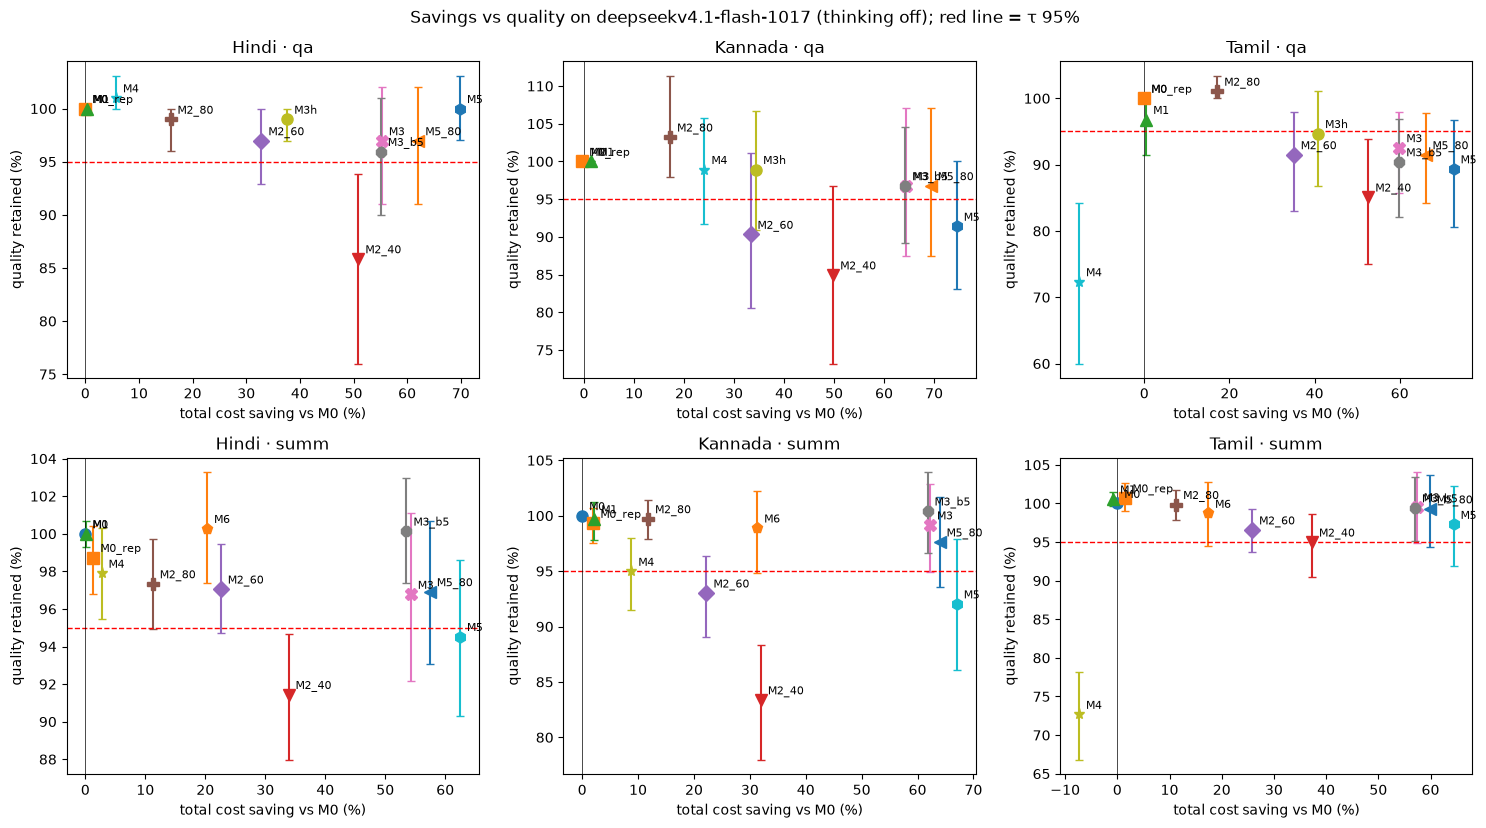

In [23]:
markers = dict(zip(METHODS, "o s ^ v D P X * h p 8 <".split()))
fig, axes = plt.subplots(len(TASKS), len(LANGS), figsize=(5 * len(LANGS), 4.2 * len(TASKS)), squeeze=False)
for r_, task in enumerate(TASKS):
    for c_, lang in enumerate(LANGS):
        ax = axes[r_][c_]; s = summary[(summary.lang == lang) & (summary.task == task)]
        for row in s.itertuples():
            ax.errorbar(row.cost_saving_pct, 100 * row.retained,
                        yerr=[[100 * (row.retained - row.ci_lo)], [100 * (row.ci_hi - row.retained)]] if not np.isnan(row.ci_lo) else None,
                        marker=markers.get(row.method, "o"), ms=8, capsize=3, label=row.method, ls="none")
            ax.annotate(row.method, (row.cost_saving_pct, 100 * row.retained), textcoords="offset points", xytext=(5, 4), fontsize=8)
        ax.axhline(100 * TAU, color="r", ls="--", lw=1); ax.axvline(0, color="k", lw=0.5)
        ax.set_title(f"{LANG[lang]['name']} · {task}"); ax.set_xlabel("total cost saving vs M0 (%)"); ax.set_ylabel("quality retained (%)")
plt.suptitle(f"Savings vs quality on {TARGET_MODEL} (thinking off); red line = τ {int(TAU*100)}%")
plt.tight_layout(); plt.savefig(FIG / "pareto.png", dpi=150); plt.show()

## I. Judge validation
**I1. Gold anchoring (QA):** does the judge's verdict agree with token-F1 against the gold answer? (F1 ≥ 0.5 is treated as correct.) Only methods with native-script answers are used, because F1 is unfair to back-translated answers.

In [24]:
def cohen_kappa(x, y):
    x, y = np.asarray(x), np.asarray(y); labels = np.union1d(x, y)
    po = (x == y).mean()
    pe = sum((x == l).mean() * (y == l).mean() for l in labels)
    return (po - pe) / (1 - pe) if pe < 1 else np.nan

qa_native = res_df[(res_df.task == "qa") & res_df.method.isin(["M0", "M0_rep", "M1", "M4"] + [m for m in METHODS if m.startswith("M2_")]) & res_df.judge_score.notna()]
rows = []
for lang, g in qa_native.groupby("lang"):
    j = (g.judge_score >= 0.5).astype(int); f = (g.f1 >= 0.5).astype(int)
    rows.append(dict(lang=lang, n=len(g), agreement=(j == f).mean(), kappa=cohen_kappa(j, f),
                     judge_correct_rate=j.mean(), f1_correct_rate=f.mean()))
display(pd.DataFrame(rows).round(3))

,lang,n,agreement,kappa,judge_correct_rate,f1_correct_rate
0,hi,350,0.923,0.213,0.989,0.911
1,kn,350,0.874,0.376,0.954,0.829
2,ta,350,0.820,0.415,0.891,0.746


**I2. Hindi spot-check (you):** the cell below writes `hindi_spotcheck.csv` with up to 30 Hindi items, **without the judge's verdict**.
Fill the `your_score` column (QA: 1 / 0.5 / 0; summaries: 1–5 overall), save, then run the next cell to see how well the judge agrees with you.

In [25]:
hi = res_df[(res_df.lang == "hi") & res_df.judge_score.notna()].sample(frac=1, random_state=SEED)
hi = pd.concat([hi[hi.task == "qa"].head(15), hi[hi.task == "summ"].head(15)])
sheet = pd.DataFrame({
    "row_id": hi.index, "task": hi.task,
    "question": [ITEM[i]["question"] for i in hi.item_id],
    "gold_answers": [" | ".join(ITEM[i]["answers"]) if ITEM[i]["answers"] else "" for i in hi.item_id],
    "context": [ITEM[i]["context"] for i in hi.item_id],
    "answer_to_grade": hi.final, "your_score": ""})
SPOT = OUT / "hindi_spotcheck.csv"
if not SPOT.exists():
    sheet.to_csv(SPOT, index=False, encoding="utf-8-sig")
    hi[["judge_score"]].to_csv(OUT / "hindi_spotcheck_judge_HIDDEN.csv", encoding="utf-8-sig")
    print("wrote", SPOT)
else:
    print(SPOT, "already exists, not overwritten")

/home/sg/REPOs/projects/onspot-hackathon/results/01_deepseek/hindi_spotcheck.csv already exists, not overwritten


In [26]:
filled = pd.read_csv(SPOT, encoding="utf-8-sig")
filled = filled[pd.to_numeric(filled.your_score, errors="coerce").notna()]
if len(filled):
    hidden = pd.read_csv(OUT / "hindi_spotcheck_judge_HIDDEN.csv", index_col=0, encoding="utf-8-sig")
    filled["human"] = [float(s) / 5 if t == "summ" else float(s) for s, t in zip(filled.your_score, filled.task)]
    filled["judge"] = hidden.loc[filled.row_id, "judge_score"].values
    for task, g in filled.groupby("task"):
        h, j = (g.human >= 0.5).astype(int), (g.judge >= 0.5).astype(int)
        print(f"{task}: n={len(g)} agreement={np.mean(h == j):.2f} kappa={cohen_kappa(h, j):.2f} "
              f"mean |human-judge|={np.mean(np.abs(g.human - g.judge)):.2f}")
else:
    print("No scores filled in yet.")

No scores filled in yet.


## J. Examples to inspect

In [27]:
def show_item(item_id, methods=METHODS):
    it = ITEM[item_id]
    print(f"[{it['lang']}/{it['task']}] Q: {it['question']}  | gold: {it['answers']}")
    g = res_df[res_df.item_id == item_id].set_index("method")
    for m in methods:
        if m in g.index:
            r = g.loc[m]
            print(f"  {m:6} in={r.prompt_tokens:>5} out={r.completion_tokens:>4} judge={r.judge_score} | {str(r.final)[:150]}")

for iid in [it["item_id"] for it in ITEMS[:: max(1, len(ITEMS) // 4)]][:4]:
    show_item(iid); print()
print("Saved to", OUT)

[hi/qa] Q: एसएलवी -3 की पहली प्रायोगिक उड़ान कब हुई थी?  | gold: ['अगस्त 1979']
  M0     in=  980 out=   8 judge=1.0 | अगस्त 1979 में
  M0_rep in=  980 out=   8 judge=1.0 | अगस्त 1979 में
  M1     in=  980 out=   8 judge=1.0 | अगस्त 1979 में
  M2_40  in=  467 out=   7 judge=1.0 | अगस्त 1979
  M2_60  in=  660 out=   7 judge=1.0 | अगस्त 1979
  M2_80  in=  830 out=   8 judge=1.0 | अगस्त 1979 में
  M3     in=  387 out=   5 judge=1.0 | अगस्त 1979
  M4     in=  904 out=   7 judge=1.0 | अगस्त 1979
  M5     in=  261 out=   5 judge=1.0 | अगस्त 1979
  M3_b5  in=  386 out=   5 judge=1.0 | अगस्त 1979
  M5_80  in=  325 out=   5 judge=1.0 | अगस्त 1979
  M3h    in=  514 out=   7 judge=1.0 | अगस्त 1979

[hi/summ] Q: None  | gold: None
  M0     in= 1785 out= 237 judge=1.0 | गुरुनानक देव ने प्रेम, सेवा और भाईचारे पर आधारित सिख धर्म की स्थापना की और ईश्वर की एकता तथा सभी मनुष्यों की समानता का उपदेश दिया। गुरु अर्जुन देव ने 
  M0_rep in= 1785 out= 181 judge=1.0 | गुरुनानक देव ने प्रेम, सेवा और भाईचारे पर 